<a href="https://colab.research.google.com/github/juliooo0/Team_A5/blob/main/Predictive_Question.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Importing Data from :

https://archive.ics.uci.edu/dataset/2/adult

In [2]:
# installing package to import data
!pip install ucimlrepo

In [3]:
# IMPORTING DATA

from ucimlrepo import fetch_ucirepo

# fetch dataset
adult = fetch_ucirepo(id=2)

# data (as pandas dataframes)
X = adult.data.features
y = adult.data.targets

# metadata
print(adult.metadata)

# variable information
print(adult.variables)


{'uci_id': 2, 'name': 'Adult', 'repository_url': 'https://archive.ics.uci.edu/dataset/2/adult', 'data_url': 'https://archive.ics.uci.edu/static/public/2/data.csv', 'abstract': 'Predict whether annual income of an individual exceeds $50K/yr based on census data. Also known as "Census Income" dataset. ', 'area': 'Social Science', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 48842, 'num_features': 14, 'feature_types': ['Categorical', 'Integer'], 'demographics': ['Age', 'Income', 'Education Level', 'Other', 'Race', 'Sex'], 'target_col': ['income'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 1996, 'last_updated': 'Tue Sep 24 2024', 'dataset_doi': '10.24432/C5XW20', 'creators': ['Barry Becker', 'Ronny Kohavi'], 'intro_paper': None, 'additional_info': {'summary': "Extraction was done by Barry Becker from the 1994 Census database.  A set of reasonably clean records was extracted using the fol

# Investigating Data
Lydia

In [4]:
# ALL IMPORTS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, recall_score, roc_auc_score, f1_score
from tqdm import tqdm
from sklearn.metrics import confusion_matrix
from sklearn.naive_bayes import MultinomialNB, GaussianNB
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.dummy import DummyClassifier

In [5]:
ogdf = pd.concat([X, y], axis=1)
display(ogdf.head())

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [6]:
ogdf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48842 non-null  int64 
 1   workclass       47879 non-null  object
 2   fnlwgt          48842 non-null  int64 
 3   education       48842 non-null  object
 4   education-num   48842 non-null  int64 
 5   marital-status  48842 non-null  object
 6   occupation      47876 non-null  object
 7   relationship    48842 non-null  object
 8   race            48842 non-null  object
 9   sex             48842 non-null  object
 10  capital-gain    48842 non-null  int64 
 11  capital-loss    48842 non-null  int64 
 12  hours-per-week  48842 non-null  int64 
 13  native-country  48568 non-null  object
 14  income          48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB


In [7]:
# TOTAL OBSERVATIONS = 48842
# TOTAL COLUMNS = 15

ogdf.shape

(48842, 15)

In [8]:
# FINDING NULL VALUES

null_values_per_column = ogdf.isnull().sum()
display(null_values_per_column)

# PROBLEMATIC COLUMNS = 'workclass', 'occupation', 'native-country'

,0
age,0
workclass,963
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,966
relationship,0
race,0
sex,0


In [9]:
# FINDING % OF NULL VALUES RELATIVE TO DF

total_observations = ogdf.shape[0]

for column in ['workclass', 'occupation', 'native-country']:
    null_count = null_values_per_column[column]
    percentage_null = (null_count / total_observations) * 100
    print(f"Percentage of null values in '{column}': {percentage_null:.2f}%")


# workclass = 1.97%
# occupation = 1.98%
# native-country = 0.56%

Percentage of null values in 'workclass': 1.97%
Percentage of null values in 'occupation': 1.98%
Percentage of null values in 'native-country': 0.56%


## Cleaning Data
Lydia

In [10]:
# Drop rows where 'workclass', 'occupation', or 'native-country' have null values
df_no_na = ogdf.dropna(subset=['workclass', 'occupation', 'native-country'])

# Display the new shape and the number of dropped rows
print(f"Original shape: {ogdf.shape}")
print(f"Cleaned shape: {df_no_na.shape}")
print(f"Number of rows dropped: {len(ogdf) - len(df_no_na)}")

# Preview the cleaned DataFrame
display(df_no_na.tail())

# 1,221 dropped (NaN only); the "?" rows are dropped later in df_q_fix

Original shape: (48842, 15)
Cleaned shape: (47621, 15)
Number of rows dropped: 1221


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
48836,33,Private,245211,Bachelors,13,Never-married,Prof-specialty,Own-child,White,Male,0,0,40,United-States,<=50K.
48837,39,Private,215419,Bachelors,13,Divorced,Prof-specialty,Not-in-family,White,Female,0,0,36,United-States,<=50K.
48839,38,Private,374983,Bachelors,13,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,50,United-States,<=50K.
48840,44,Private,83891,Bachelors,13,Divorced,Adm-clerical,Own-child,Asian-Pac-Islander,Male,5455,0,40,United-States,<=50K.
48841,35,Self-emp-inc,182148,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,60,United-States,>50K.


In [11]:
# Found 4 diff income inputs
# Training set > 50k VS Testing set >50k.

df_no_na['income'].value_counts()

,count
income,
<=50K,24720
<=50K.,11360
>50K,7841
>50K.,3700


consolidating income to 2 diff income values by dropping the period

In [12]:
df_50k_fix = df_no_na.copy()
df_50k_fix['income'] = df_50k_fix['income'].str.replace('.', '', regex=False)
df_50k_fix['income'].value_counts()

,count
income,
<=50K,36080
>50K,11541


found more Null values that had ? instead

In [13]:
# values with "?"

(df_50k_fix == '?').sum()

# workclass, occupation, and native country all have ? in data

,0
age,0
workclass,1836
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,1843
relationship,0
race,0
sex,0


In [14]:
# changing the ? values into NaN values so that they can be dropped with dropna

df_q_fix = df_50k_fix.replace('?', np.nan).dropna()
(df_q_fix == '?').sum()

,0
age,0
workclass,0
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,0
relationship,0
race,0
sex,0


In [15]:
# checking for white space in names

for col in df_q_fix.select_dtypes(include='object').columns:
    has_space = (df_q_fix[col] != df_q_fix[col].str.strip()).any()
    print(col, has_space)

workclass False
education False
marital-status False
occupation False
relationship False
race False
sex False
native-country False
income False


In [16]:
#checking for duplicates

df_q_fix.duplicated().sum()

np.int64(47)

In [17]:
# looking into the 47 flagged duplicates

df_q_fix[df_q_fix.duplicated(keep=False)].sort_values(list(df_q_fix.columns))

# since they are so few, they wont effect data, and could just be crazy coincidences. + the only crazy coincidence part is final weight, and we are dropping that anyway.

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
24667,17,Private,153021,12th,8,Never-married,Sales,Own-child,White,Female,0,0,20,United-States,<=50K
36713,17,Private,153021,12th,8,Never-married,Sales,Own-child,White,Female,0,0,20,United-States,<=50K
36461,18,Self-emp-inc,378036,12th,8,Never-married,Farming-fishing,Own-child,White,Male,0,0,10,United-States,<=50K
48521,18,Self-emp-inc,378036,12th,8,Never-married,Farming-fishing,Own-child,White,Male,0,0,10,United-States,<=50K
17673,19,Private,97261,HS-grad,9,Never-married,Farming-fishing,Not-in-family,White,Male,0,0,40,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21875,49,Private,31267,7th-8th,4,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40,United-States,<=50K
7053,49,Self-emp-not-inc,43479,Some-college,10,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40,United-States,<=50K
22494,49,Self-emp-not-inc,43479,Some-college,10,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40,United-States,<=50K
2303,90,Private,52386,Some-college,10,Never-married,Other-service,Not-in-family,Asian-Pac-Islander,Male,0,0,35,United-States,<=50K


# Encoding step of cleaning:

Lydia

Claude AI usage for writing and debugging code from here onward.

## Starting with income <=50 k vs. >50K

## =50k : 0
## >50k : 1

In [18]:
# code income to be 0 and 1

dfbinaryinc = df_q_fix.copy()
dfbinaryinc['income'] = dfbinaryinc['income'].map({'<=50K': 0, '>50K': 1})
dfbinaryinc['income'].value_counts()

,count
income,
0,34014
1,11208


In [19]:
# baseline ratio for the clean data set:

baseline = dfbinaryinc['income'].value_counts(normalize=True).max()
print(f'Baseline accuracy: {baseline:.1%}')

Baseline accuracy: 75.2%


baseline accuracy of 75.2% means if the model always predicts <=50k, the model will be right 75% of the time.

Looking at dropping either education or education_num (redundant)

In [20]:
pd.crosstab(dfbinaryinc['education'], dfbinaryinc['education-num'])

# perfect one to one match bc each row only has one non-zero number

education-num,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
education,,,,,,,,,,,,,,,,
10th,0,0,0,0,0,1223,0,0,0,0,0,0,0,0,0,0
11th,0,0,0,0,0,0,1619,0,0,0,0,0,0,0,0,0
12th,0,0,0,0,0,0,0,577,0,0,0,0,0,0,0,0
1st-4th,0,222,0,0,0,0,0,0,0,0,0,0,0,0,0,0
5th-6th,0,0,449,0,0,0,0,0,0,0,0,0,0,0,0,0
7th-8th,0,0,0,823,0,0,0,0,0,0,0,0,0,0,0,0
9th,0,0,0,0,676,0,0,0,0,0,0,0,0,0,0,0
Assoc-acdm,0,0,0,0,0,0,0,0,0,0,0,1507,0,0,0,0
Assoc-voc,0,0,0,0,0,0,0,0,0,0,1959,0,0,0,0,0


dropping education and keeping education_num bc it is already in a numeric format

In [21]:
df_no_catedu = dfbinaryinc.drop(columns=['education']).copy()
df_no_catedu.shape

# lost one feature 15->14

(45222, 14)

Looking at Native Country feature
* has 40 unique values

In [22]:
df_no_catedu['native-country'].value_counts(normalize=True).round(3)

# 91% of the data is US born, not enough non native to justify making 40 new columns, would make data noisier and cause overfitting

,proportion
native-country,
United-States,0.913
Mexico,0.020
Philippines,0.006
Germany,0.004
Puerto-Rico,0.004
Canada,0.004
El-Salvador,0.003
India,0.003
Cuba,0.003


In [23]:
# grouping native country into US vs other

df_country = df_no_catedu.copy()
df_country['native-country'] = np.where(df_country['native-country'] == 'United-States', 'United-States', 'Other')
df_country['native-country'].value_counts()

,count
native-country,
United-States,41292
Other,3930


Encoding the other categorical variables

In [24]:
# looking at the change in column #

text_cols = df_country.select_dtypes(include='object').columns
summary = pd.DataFrame({
    'categories': df_country[text_cols].nunique(),
    'binary_columns_after_drop_first': df_country[text_cols].nunique() - 1
})
print(summary)
print('\nTotal new binary columns:', summary['binary_columns_after_drop_first'].sum())
print('Numeric columns kept:', len(df_country.columns) - len(text_cols))

                categories  binary_columns_after_drop_first
workclass                7                                6
marital-status           7                                6
occupation              14                               13
relationship             6                                5
race                     5                                4
sex                      2                                1
native-country           2                                1

Total new binary columns: 36
Numeric columns kept: 7


In [25]:
# cleaned and encoded df = encodeddf

encodeddf = pd.get_dummies(df_country, drop_first=True, dtype=int)
encodeddf.shape

(45222, 43)

In [26]:
# dropping fnlwgt justification - it is just the weight a person holds in the census, no correl with income
# could confuse the model and cause overfitting

encodeddf['fnlwgt'].corr(encodeddf['income'])


np.float64(-0.007263912940611196)

In [27]:
dfclean = encodeddf.drop(columns=['fnlwgt']).copy()
dfclean.shape

(45222, 42)

# Train / Test Split

Lydia

In [28]:

X = dfclean.drop(columns=['income'])
y = dfclean['income']

# split test and train 80/20, stratify so the share of 1s (>50k) is even (24.8 over 50k income)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(X_train.shape, X_test.shape)
print(y_train.mean().round(3), y_test.mean().round(3))

(36177, 41) (9045, 41)
0.248 0.248


In [29]:
# 5-fold CV setup, shared by every model so comparisons are fair
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

## LEAKAGE CHECK
lydia

In [30]:
# leakage check: is capital-gain / capital-loss "known before" income, or part of it?

# 1. how strongly do they line up with the outcome?
check = X_train[['capital-gain', 'capital-loss']].copy()
check['income'] = y_train
print('Share >50K, capital-gain = 0     :', round(check.loc[check['capital-gain'] == 0, 'income'].mean(), 3))
print('Share >50K, capital-gain > 0     :', round(check.loc[check['capital-gain'] > 0, 'income'].mean(), 3))
print('Share >50K, capital-gain = 99,999:', round(check.loc[check['capital-gain'] == 99999, 'income'].mean(), 3))

# 2. how much does a random forest lean on them?
rf_check = RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1,
                                  max_depth=20, min_samples_leaf=5, max_features=0.5)
rows = []
for name, cols_out in [('with capital columns', []),
                       ('without capital columns', ['capital-gain', 'capital-loss'])]:
    s = cross_validate(rf_check, X_train.drop(columns=cols_out), y_train, cv=cv,
                       scoring=['accuracy', 'recall', 'roc_auc'])
    rows.append({'version': name, 'accuracy': s['test_accuracy'].mean(),
                 'recall': s['test_recall'].mean(), 'auc': s['test_roc_auc'].mean()})
pd.DataFrame(rows).set_index('version').round(3)

Share >50K, capital-gain = 0     : 0.213
Share >50K, capital-gain > 0     : 0.627
Share >50K, capital-gain = 99,999: 1.0


,accuracy,recall,auc
version,,,
with capital columns,0.862,0.618,0.916
without capital columns,0.834,0.576,0.887


## LEAKAGE DECISION: KEEPING CAPITAL-GAIN AND CAPITAL-LOSS

- checked capital-gain/loss for leakage: 99,999 → 100% >50k, any gain → 62.7% vs 21.3%
- forest with them 86.2 acc vs 83.4 without
- discussed with professor: high correlation with the outcome is not automatically leakage
- kept them; instead checking whether the model is fair across subgroups (see subgroup section)

# OUTLIERS

Lydia



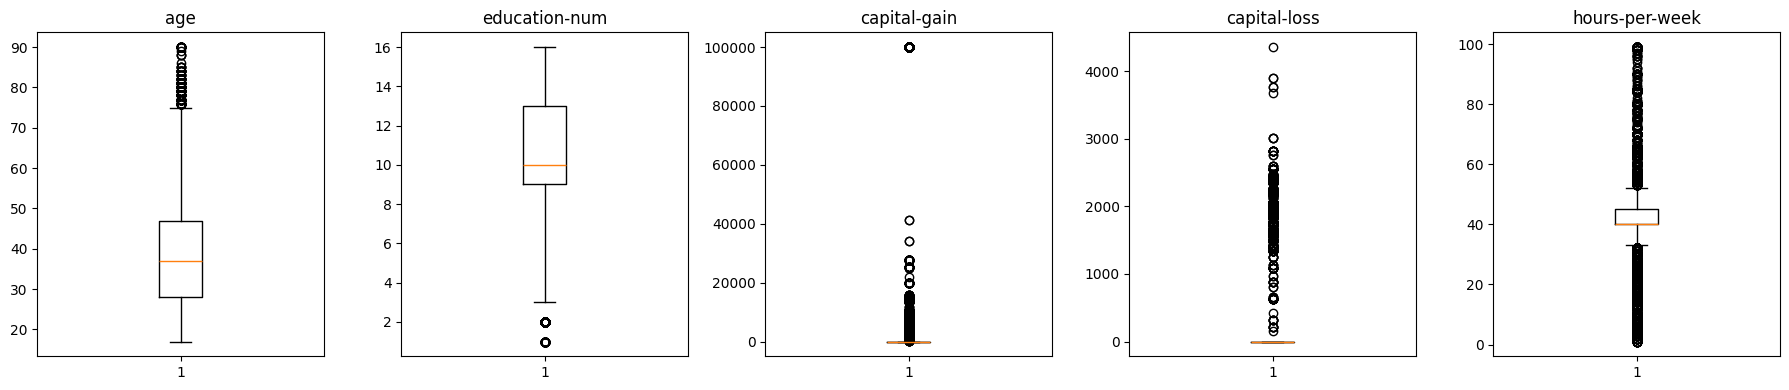

In [31]:
num_cols = ['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

fig, axes = plt.subplots(1, len(num_cols), figsize=(18, 4))
for ax, col in zip(axes, num_cols):
    ax.boxplot(X_train[col])
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Outlier decisions (based on boxplots of training data):**
- **age:** outliers at 76–90 are real people, so kept
- **education-num:** values 1–2 (Preschool, 1st–4th) are rare but real, so kept
- **capital-gain:** mostly 0, with a cluster at 99,999 that is likely top-coded. Rows kept; log transform tested
- **capital-loss:** mostly 0 with real losses up to ~4,300. Rows kept; log transform tested
- **hours-per-week:** extremes on both ends are real. Capping at the 1st/99th percentile (10–80 hrs) tested

All 4 versions (base, log, cap, cap + log) are compared with 5-fold CV on the training data.

# TESTING OUTLIER APPROACHES
Making 4 different forms of df: base, log of capital-gain/loss, capped hours-per-week, and cap + log.

In [32]:
log_cols = ['capital-gain', 'capital-loss']

# cutoffs for capping hours-per-week, from train only
low = X_train['hours-per-week'].quantile(0.01)
high = X_train['hours-per-week'].quantile(0.99)

# 1. base
X_train_base, X_test_base = X_train.copy(), X_test.copy()

# 2. log capital-gain and capital-loss
X_train_log, X_test_log = X_train.copy(), X_test.copy()
X_train_log[log_cols] = np.log1p(X_train_log[log_cols])
X_test_log[log_cols] = np.log1p(X_test_log[log_cols])

# 3. cap hours-per-week, no log
X_train_cap, X_test_cap = X_train.copy(), X_test.copy()
X_train_cap['hours-per-week'] = X_train_cap['hours-per-week'].clip(low, high)
X_test_cap['hours-per-week'] = X_test_cap['hours-per-week'].clip(low, high)

# 4. cap + log
X_train_caplog, X_test_caplog = X_train_log.copy(), X_test_log.copy()
X_train_caplog['hours-per-week'] = X_train_caplog['hours-per-week'].clip(low, high)
X_test_caplog['hours-per-week'] = X_test_caplog['hours-per-week'].clip(low, high)

print('Cap cutoffs:', low, high)

versions = {
    'base': (X_train_base, X_test_base),
    'log': (X_train_log, X_test_log),
    'cap': (X_train_cap, X_test_cap),
    'cap + log': (X_train_caplog, X_test_caplog),
}

Cap cutoffs: 10.0 80.0


In [32]:
# more official baseline using dummy classifier
# what a model that ignores all inputs wold predict

dummy = DummyClassifier(strategy='most_frequent')

dummy_cv = cross_validate(dummy, X_train_base, y_train, cv=cv,
                          scoring=['accuracy', 'recall', 'roc_auc'])
print('Dummy CV accuracy:', round(dummy_cv['test_accuracy'].mean(), 3),
      '| Recall:', round(dummy_cv['test_recall'].mean(), 3),
      '| AUC:', round(dummy_cv['test_roc_auc'].mean(), 3))

Dummy CV accuracy: 0.752 | Recall: 0.0 | AUC: 0.5


## RE-VISITING MISSING VALUES: WHETHER WE DROP THEM OR FILL THEM

In [33]:
# testing a fill-in option for missing values instead of dropping the rows
# missing workclass / occupation / native-country become their own category, "Unknown"

df_fill = ogdf.copy()
df_fill['income'] = df_fill['income'].str.replace('.', '', regex=False).map({'<=50K': 0, '>50K': 1})
df_fill = df_fill.replace('?', np.nan)
for col in ['workclass', 'occupation', 'native-country']:
    df_fill[col] = df_fill[col].fillna('Unknown')

# same steps as the main cleaning: drop education + fnlwgt, group country, binary encode
df_fill = df_fill.drop(columns=['education', 'fnlwgt'])
df_fill['native-country'] = np.where(df_fill['native-country'] == 'United-States', 'United-States', 'Other')
df_fill = pd.get_dummies(df_fill, drop_first=True, dtype=int)
print('Rows kept:', len(df_fill), 'vs', len(dfclean), 'when dropping')

# same 80/20 stratified split
X_fill = df_fill.drop(columns=['income'])
y_fill = df_fill['income']
X_train_fill, X_test_fill, y_train_fill, y_test_fill = train_test_split(
    X_fill, y_fill, test_size=0.2, stratify=y_fill, random_state=42)

# compare with logit, same 5-fold CV
pipe_logit = Pipeline([
    ('scale', ColumnTransformer([('num', StandardScaler(), num_cols)], remainder='passthrough')),
    ('logit', LogisticRegression(max_iter=1000)),
])
rows = []
for name, Xtr, ytr in [('drop rows', X_train_base, y_train), ('fill "Unknown"', X_train_fill, y_train_fill)]:
    s = cross_validate(pipe_logit, Xtr, ytr, cv=cv, scoring=['accuracy', 'recall', 'roc_auc'])
    rows.append({'missing values': name, 'accuracy': s['test_accuracy'].mean(),
                 'recall': s['test_recall'].mean(), 'auc': s['test_roc_auc'].mean()})
pd.DataFrame(rows).set_index('missing values').round(3)

Rows kept: 48842 vs 45222 when dropping


,accuracy,recall,auc
missing values,,,
drop rows,0.848,0.606,0.905
"fill ""Unknown""",0.851,0.597,0.906


# LOGIT

Lydia

In [34]:
# logit:

def cv_logit(Xtr):
    pipe = Pipeline([
        ('scale', ColumnTransformer([('num', StandardScaler(), num_cols)], remainder='passthrough')),
        ('logit', LogisticRegression(max_iter=1000)),
    ])
    scores = cross_validate(pipe, Xtr, y_train, cv=cv, scoring=['accuracy', 'recall', 'roc_auc'])
    return {
        'accuracy': scores['test_accuracy'].mean(),
        'recall': scores['test_recall'].mean(),
        'auc': scores['test_roc_auc'].mean(),
    }

cv_results = pd.DataFrame(
    [cv_logit(v[0]) for v in versions.values()],
    index=versions.keys()
)
cv_results.round(3)

,accuracy,recall,auc
base,0.848,0.606,0.905
log,0.842,0.594,0.898
cap,0.848,0.607,0.905
cap + log,0.842,0.595,0.898


In [35]:
# logit: tuning class_weight (None vs extra weight on the rarer >50K class)
rows = []
for cw in [None, 'balanced']:
    logit_pipe = Pipeline([
        ('scale', ColumnTransformer([('num', StandardScaler(), num_cols)], remainder='passthrough')),
        ('logit', LogisticRegression(max_iter=1000, class_weight=cw)),
    ])
    s = cross_validate(logit_pipe, X_train_base, y_train, cv=cv,
                       scoring=['accuracy', 'recall', 'roc_auc'])
    rows.append({'class_weight': str(cw), 'accuracy': s['test_accuracy'].mean(),
                 'recall': s['test_recall'].mean(), 'auc': s['test_roc_auc'].mean()})

pd.DataFrame(rows).set_index('class_weight').round(3)

,accuracy,recall,auc
class_weight,,,
None,0.848,0.606,0.905
balanced,0.808,0.842,0.905


In [36]:

pipe = Pipeline([
    ('scale', ColumnTransformer([('num', StandardScaler(), num_cols)], remainder='passthrough')),
    ('logit', LogisticRegression(max_iter=1000)),
])

probs = cross_val_predict(pipe, X_train_base, y_train, cv=cv, method='predict_proba')[:, 1]

thresholds = np.arange(0.30, 0.71, 0.05)
thr_results = pd.DataFrame({
    'threshold': thresholds,
    'accuracy': [accuracy_score(y_train, (probs >= t).astype(int)) for t in thresholds]
})
thr_results.round(3)

,threshold,accuracy
0,0.30,0.825
1,0.35,0.836
2,0.40,0.844
3,0.45,0.849
4,0.50,0.848
5,0.55,0.847
6,0.60,0.845
7,0.65,0.840
8,0.70,0.832


In [37]:
# checking accuracy across all 5 folds for thresholds 0.45 vs 0.50
# keeping 0.50: 0.45 loses to 0.50 in 4 of 5 folds, and its avg accuracy is slightly lower

rows = []
for i, (_, idx) in enumerate(cv.split(X_train_base, y_train)):
    y_fold = y_train.iloc[idx]
    p_fold = probs[idx]
    rows.append({
        'fold': i + 1,
        'acc_0.45': accuracy_score(y_fold, (p_fold >= 0.45).astype(int)),
        'acc_0.50': accuracy_score(y_fold, (p_fold >= 0.50).astype(int)),
    })

fold_df = pd.DataFrame(rows)
fold_df['diff'] = fold_df['acc_0.45'] - fold_df['acc_0.50']
print(fold_df.round(4))
print('\nStd across folds:')
print(fold_df[['acc_0.45', 'acc_0.50']].std().round(4))

   fold  acc_0.45  acc_0.50    diff
0     1    0.8494    0.8467  0.0026
1     2    0.8494    0.8492  0.0001
2     3    0.8423    0.8449 -0.0026
3     4    0.8509    0.8499  0.0010
4     5    0.8531    0.8511  0.0019

Std across folds:
acc_0.45    0.0040
acc_0.50    0.0025
dtype: float64


LOGIT
- cv accuracy 0.832, recall 0.566, auc 0.884
- base and cap identical, capping hours did nothing
- threshold: 0.50 best (0.832), 0.45 close (0.831)
- fold check: 0.45 lost to 0.50 in 4 of 5 folds, so keep 0.50
- class_weight: None 0.832 acc / 0.566 recall; balanced 0.787 acc / 0.839 recall; auc same 0.884 both
- balanced trades 4.5 pts accuracy for 27 pts recall; same auc = same ranking, just a lower bar for predicting >50k


## KNN

Lydia

In [38]:
# KNN: trying different k values with 5-fold CV on the training data

results = []

for k in tqdm(range(1, 102, 10)):
    pipe_knn = Pipeline([
        ('scale', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=k)),
    ])
    scores = cross_validate(pipe_knn, X_train_base, y_train, cv=cv,
                            scoring=['accuracy', 'recall', 'roc_auc'], n_jobs=-1)
    results.append({
        'k': k,
        'accuracy': scores['test_accuracy'].mean(),
        'recall': scores['test_recall'].mean(),
        'auc': scores['test_roc_auc'].mean(),
    })

knn_results_df = pd.DataFrame(results)
knn_results_df.round(3)

100%|██████████| 11/11 [03:27<00:00, 18.91s/it]


,k,accuracy,recall,auc
0,1,0.798,0.584,0.726
1,11,0.833,0.587,0.872
2,21,0.835,0.579,0.880
3,31,0.834,0.575,0.882
4,41,0.834,0.574,0.882
5,51,0.833,0.571,0.882
6,61,0.833,0.569,0.881
7,71,0.832,0.567,0.880
8,81,0.832,0.567,0.879
9,91,0.831,0.561,0.878


In [39]:
# KNN (k=21): tuning weights, every neighbor votes equally ('uniform') vs closer neighbors count more ('distance')
rows = []
for w in ['uniform', 'distance']:
    pipe_knn = Pipeline([
        ('scale', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=21, weights=w)),
    ])
    s = cross_validate(pipe_knn, X_train_base, y_train, cv=cv,
                       scoring=['accuracy', 'recall', 'roc_auc'], n_jobs=-1)
    rows.append({'weights': w, 'accuracy': s['test_accuracy'].mean(),
                 'recall': s['test_recall'].mean(), 'auc': s['test_roc_auc'].mean()})

pd.DataFrame(rows).set_index('weights').round(3)

,accuracy,recall,auc
weights,,,
uniform,0.835,0.579,0.88
distance,0.828,0.568,0.85


Max CV accuracy = 0.835 | Best k = 21


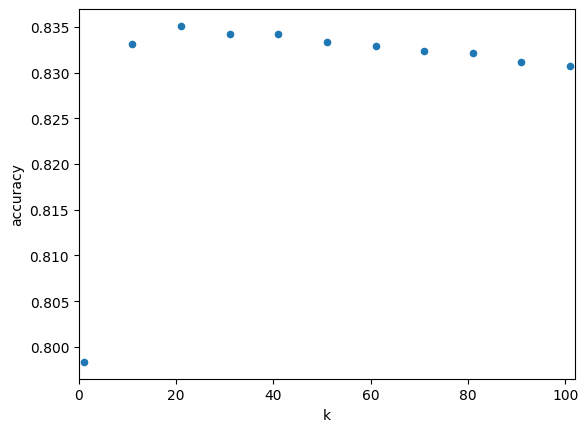

In [40]:
# Plot CV accuracy against k, and find the best k
knn_results_df.plot.scatter(x='k', y='accuracy', xlim=[0,102]);

best_row = knn_results_df['accuracy'].idxmax()
print('Max CV accuracy =', round(knn_results_df.loc[best_row, 'accuracy'], 3),
      '| Best k =', knn_results_df.loc[best_row, 'k'])

Logit still is a better test bc of higher accuracy

testing k=51 with the 2 outlier versions (base vs capped hours)

In [41]:
# testing k=21 with the 4 outlier versions (base, log, cap, cap + log)

results = []
for name, (Xtr, Xte) in tqdm(versions.items()):
    pipe_knn = Pipeline([
        ('scale', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=21)),
    ])
    scores = cross_validate(pipe_knn, Xtr, y_train, cv=cv,
                            scoring=['accuracy', 'recall', 'roc_auc'], n_jobs=-1)
    results.append({
        'version': name,
        'accuracy': scores['test_accuracy'].mean(),
        'recall': scores['test_recall'].mean(),
        'auc': scores['test_roc_auc'].mean(),
    })

knn_versions_df = pd.DataFrame(results).set_index('version')
knn_versions_df.round(3)

100%|██████████| 4/4 [01:10<00:00, 17.61s/it]


,accuracy,recall,auc
version,,,
base,0.835,0.579,0.880
log,0.836,0.601,0.884
cap,0.834,0.578,0.880
cap + log,0.836,0.599,0.884


KNN
- k tested 1 to 101 (steps of 10), widened bc 51 was the edge of the first range
- k=1 worst (0.780, overfits); plateau from k=21 on
- best k = 51 (0.828), tied with 61; accuracy slowly drops after 61
- cap version same as base
- weights: uniform 0.828 acc / 0.578 recall / 0.874 auc; distance 0.818 / 0.561 / 0.830, so keep uniform
- k=51 base vs cap: identical (0.828), capping does nothing

## NAIVE BAYES

Lydia

In [42]:
# Naive Bayes: comparing Multinomial (class lab) vs Gaussian, across the 4 outlier versions
# no scaling: NB doesn't need it, and scaling creates negatives that break MultinomialNB

results = []
for name, (Xtr, Xte) in tqdm(versions.items()):
    for nb_name, nb in [('Multinomial', MultinomialNB()), ('Gaussian', GaussianNB())]:
        scores = cross_validate(nb, Xtr, y_train, cv=cv,
                                scoring=['accuracy', 'recall', 'roc_auc'], n_jobs=-1)
        results.append({
            'nb_type': nb_name,
            'version': name,
            'accuracy': scores['test_accuracy'].mean(),
            'recall': scores['test_recall'].mean(),
            'auc': scores['test_roc_auc'].mean(),
        })

nb_results_df = pd.DataFrame(results).set_index(['nb_type', 'version'])
nb_results_df.round(3)

100%|██████████| 4/4 [00:02<00:00,  1.44it/s]


,,accuracy,recall,auc
nb_type,version,,,
Multinomial,base,0.774,0.213,0.402
Gaussian,base,0.823,0.732,0.887
Multinomial,log,0.781,0.360,0.847
Gaussian,log,0.728,0.868,0.857
Multinomial,cap,0.774,0.213,0.402
Gaussian,cap,0.823,0.733,0.887
Multinomial,cap + log,0.781,0.360,0.847
Gaussian,cap + log,0.728,0.869,0.857


In [43]:
# Gaussian NB: tuning var_smoothing (adds a small amount to every variance for stability)
# and priors (use the real 75/25 class split, or assume 50/50)
nb_grid = {
    'var_smoothing': [1e-11, 1e-9, 1e-7, 1e-5, 1e-3, 1e-1],
    'priors': [None, [0.5, 0.5]],
}
nb_search = GridSearchCV(GaussianNB(), nb_grid, cv=cv,
                         scoring=['accuracy', 'recall', 'roc_auc'], refit='accuracy', n_jobs=-1)
nb_search.fit(X_train_base, y_train)

nb_grid_df = pd.DataFrame(nb_search.cv_results_)[
    ['param_var_smoothing', 'param_priors', 'mean_test_accuracy', 'mean_test_recall', 'mean_test_roc_auc']]
print('Best:', nb_search.best_params_)
nb_grid_df.round(3)

Best: {'priors': None, 'var_smoothing': 1e-09}


,param_var_smoothing,param_priors,mean_test_accuracy,mean_test_recall,mean_test_roc_auc
0,0.000,None,0.760,0.855,0.871
1,0.000,None,0.823,0.732,0.887
2,0.000,None,0.789,0.312,0.836
3,0.000,None,0.788,0.312,0.781
4,0.001,None,0.790,0.312,0.773
5,0.100,None,0.794,0.175,0.771
6,0.000,"[0.5, 0.5]",0.753,0.861,0.871
7,0.000,"[0.5, 0.5]",0.797,0.826,0.887
8,0.000,"[0.5, 0.5]",0.786,0.312,0.836
9,0.000,"[0.5, 0.5]",0.785,0.312,0.781


NAIVE BAYES
- multinomial 0.794 acc, 0.690 recall, 0.850 auc
- gaussian 0.713 acc (below the 0.752 dummy), 0.862 recall, 0.840 auc
- flipped from before: with capital columns gaussian won and multinomial was bad
- reason: multinomial treated huge capital-gain numbers as counts; without them it works
- gaussian over-predicts >50k, high recall but accuracy below baseline
- cap same as base

- alpha (0.01 to 10): no effect, 0.794 acc at every value; flat, so not a real edge
- fit_prior True: 0.794 acc / 0.691 recall; False (assume 50/50): 0.732 acc / 0.852 recall
- fit_prior False falls below the 0.752 dummy; same auc 0.850 both = same ranking, lower bar for >50k
- final NB: multinomial, fit_prior True, alpha 1 (default)

## DECISION TREE

Lydia

In [44]:
# full tree (no limits)
full_clf = DecisionTreeClassifier(random_state=0)
full_clf.fit(X_train_base, y_train)

print('Number of nodes:', full_clf.tree_.node_count)
print('Train accuracy:', round(accuracy_score(y_train, full_clf.predict(X_train_base)), 3))

full_cv = cross_validate(full_clf, X_train_base, y_train, cv=cv, scoring='accuracy')
print('CV accuracy:', round(full_cv['test_score'].mean(), 3))

# train accuracy vs CV accuracy shows overfitting:

# train accuracy vs CV accuracy shows overfitting:
# Number of nodes: 13211
# Train accuracy: 0.972
# CV accuracy: 0.813

Number of nodes: 13211
Train accuracy: 0.972
CV accuracy: 0.813


In [45]:
# grid search over tree settings, scored with the same 5-fold CV as the other models
param_grid = {
    'max_depth': [5, 8, 10, 15, 20],
    'min_samples_leaf': [2, 5, 10, 20, 50, 100],
    'min_impurity_decrease': [0, 0.0005, 0.001],
}

gridSearch = GridSearchCV(DecisionTreeClassifier(random_state=0), param_grid,
                          cv=cv, scoring='accuracy', n_jobs=-1)
gridSearch.fit(X_train_base, y_train)

print('Best CV accuracy:', round(gridSearch.best_score_, 3))
print('Best parameters:', gridSearch.best_params_)

# recall + auc for the best tree, to add to the scoreboard
best_cv = cross_validate(gridSearch.best_estimator_, X_train_base, y_train, cv=cv,
                         scoring=['accuracy', 'recall', 'roc_auc'])
print('Recall:', round(best_cv['test_recall'].mean(), 3),
      '| AUC:', round(best_cv['test_roc_auc'].mean(), 3))

# Best CV accuracy: 0.854
# Best parameters: {'max_depth': 10, 'min_impurity_decrease': 0, 'min_samples_leaf': 10}
# Recall: 0.583 | AUC: 0.901

Best CV accuracy: 0.854
Best parameters: {'max_depth': 10, 'min_impurity_decrease': 0, 'min_samples_leaf': 10}
Recall: 0.583 | AUC: 0.901


DECISION TREE
- full tree: 15,481 nodes, train 0.962, cv 0.776, big gap = overfitting
- best: max_depth 15, min_samples_leaf 50, min_impurity_decrease 0
- cv accuracy 0.831, recall 0.573, auc 0.878
- leaf 50 in middle of range (10 to 100), not at the edge

## RANDOM FOREST

Lydia

In [46]:
# random forest: 500 trees, scored with the same 5-fold CV as the other models
rf = RandomForestClassifier(n_estimators=500, random_state=0, criterion='gini', n_jobs=-1)

rf_cv = cross_validate(rf, X_train_base, y_train, cv=cv,
                       scoring=['accuracy', 'recall', 'roc_auc'])
print('CV accuracy:', round(rf_cv['test_accuracy'].mean(), 3),
      '| Recall:', round(rf_cv['test_recall'].mean(), 3),
      '| AUC:', round(rf_cv['test_roc_auc'].mean(), 3))

CV accuracy: 0.845 | Recall: 0.62 | AUC: 0.894


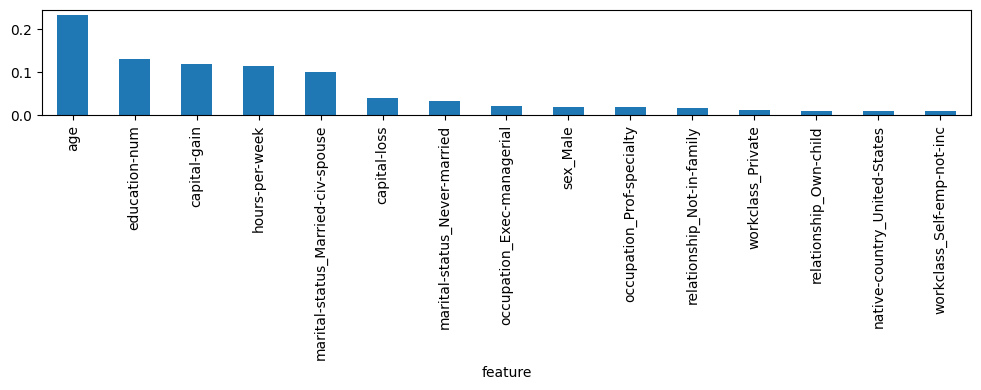

In [47]:
# which features the forest relied on most
rf.fit(X_train_base, y_train)
importance_df = pd.DataFrame({'feature': X_train_base.columns, 'importance': rf.feature_importances_})
importance_df = importance_df.sort_values('importance', ascending=False).head(15)

importance_df.plot(kind='bar', x='feature', legend=False, figsize=(10, 4))
plt.tight_layout()
plt.show()

In [48]:
# grid search for random forest, same 5-fold CV as the other models
rf_grid = {
    'max_depth': [10, 15, 20, None],
    'min_samples_leaf': [1, 5, 10],
    'max_features': ['sqrt', 0.5, 0.7],
}

rf_search = GridSearchCV(RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1),
                         rf_grid, cv=cv, scoring='accuracy', verbose=1)
rf_search.fit(X_train_base, y_train)

print('Best CV accuracy:', round(rf_search.best_score_, 3))
print('Best parameters:', rf_search.best_params_)

best_rf_cv = cross_validate(rf_search.best_estimator_, X_train_base, y_train, cv=cv,
                            scoring=['accuracy', 'recall', 'roc_auc'])
print('Recall:', round(best_rf_cv['test_recall'].mean(), 3),
      '| AUC:', round(best_rf_cv['test_roc_auc'].mean(), 3))

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best CV accuracy: 0.862
Best parameters: {'max_depth': 20, 'max_features': 0.5, 'min_samples_leaf': 5}
Recall: 0.618 | AUC: 0.916


RANDOM FOREST
- default (no limits): 0.812 acc, 0.557 recall, 0.859 auc, overfits like the full tree
- best: max_depth 20, min_samples_leaf 5, max_features sqrt
- final 500 trees: cv accuracy 0.837, recall 0.555, auc 0.891
- best model on accuracy and auc

In [49]:
# final random forest: 500 trees with the best settings from the grid search
# (depth 20, leaf 5, max_features 0.5)
rf_best = RandomForestClassifier(n_estimators=500, random_state=0, n_jobs=-1,
                                 max_depth=20, min_samples_leaf=5, max_features=0.5)

rf_best_cv = cross_validate(rf_best, X_train_base, y_train, cv=cv,
                            scoring=['accuracy', 'recall', 'roc_auc'])
print('CV accuracy:', round(rf_best_cv['test_accuracy'].mean(), 3),
      '| Recall:', round(rf_best_cv['test_recall'].mean(), 3),
      '| AUC:', round(rf_best_cv['test_roc_auc'].mean(), 3))

CV accuracy: 0.862 | Recall: 0.617 | AUC: 0.916


## NEURAL NETWORKS
Lydia

In [50]:
# neural network: comparing architectures + activations with 5-fold CV on training data (base version)
# MinMax scaling (0-1) like the lab, fit on train only inside each fold
# tol=1e-8 and max_iter=2000 = the lab's fix for networks that stop training too early

results = []
for layers in tqdm([(2,), (5,), (2, 2, 2), (5, 5, 5)]):
    for act in ['logistic', 'relu']:
        pipe_nn = Pipeline([
            ('scale', ColumnTransformer([('num', MinMaxScaler(), num_cols)], remainder='passthrough')),
            ('nn', MLPClassifier(hidden_layer_sizes=layers, activation=act, solver='lbfgs',
                                 tol=1e-8, max_iter=2000, random_state=1)),
        ])
        scores = cross_validate(pipe_nn, X_train_base, y_train, cv=cv,
                                scoring=['accuracy', 'recall', 'roc_auc'], n_jobs=-1)
        results.append({
            'layers': str(layers),
            'activation': act,
            'accuracy': scores['test_accuracy'].mean(),
            'recall': scores['test_recall'].mean(),
            'auc': scores['test_roc_auc'].mean(),
        })

nn_results_df = pd.DataFrame(results)
nn_results_df['vs_baseline'] = nn_results_df['accuracy'] - baseline
nn_results_df.round(3)

100%|██████████| 4/4 [12:22<00:00, 185.69s/it]


,layers,activation,accuracy,recall,auc,vs_baseline
0,"(2,)",logistic,0.852,0.625,0.908,0.099
1,"(2,)",relu,0.848,0.608,0.905,0.096
2,"(5,)",logistic,0.854,0.628,0.909,0.102
3,"(5,)",relu,0.850,0.623,0.908,0.098
4,"(2, 2, 2)",logistic,0.848,0.608,0.905,0.096
5,"(2, 2, 2)",relu,0.752,0.000,0.500,0.000
6,"(5, 5, 5)",logistic,0.852,0.621,0.908,0.100
7,"(5, 5, 5)",relu,0.851,0.621,0.907,0.099


In [51]:
# widening the range: (5,) won and was the largest single layer tested, so trying bigger ones

more = []
for layers in tqdm([(10,), (20,)]):
    for act in ['logistic', 'relu']:
        pipe_nn = Pipeline([
            ('scale', ColumnTransformer([('num', MinMaxScaler(), num_cols)], remainder='passthrough')),
            ('nn', MLPClassifier(hidden_layer_sizes=layers, activation=act, solver='lbfgs',
                                 tol=1e-8, max_iter=2000, random_state=1)),
        ])
        scores = cross_validate(pipe_nn, X_train_base, y_train, cv=cv,
                                scoring=['accuracy', 'recall', 'roc_auc'], n_jobs=-1)
        more.append({
            'layers': str(layers),
            'activation': act,
            'accuracy': scores['test_accuracy'].mean(),
            'recall': scores['test_recall'].mean(),
            'auc': scores['test_roc_auc'].mean(),
        })

more_df = pd.DataFrame(more)
more_df['vs_baseline'] = more_df['accuracy'] - baseline
nn_results_df = pd.concat([nn_results_df, more_df], ignore_index=True)
nn_results_df.round(3)

100%|██████████| 2/2 [11:51<00:00, 355.71s/it]


,layers,activation,accuracy,recall,auc,vs_baseline
0,"(2,)",logistic,0.852,0.625,0.908,0.099
1,"(2,)",relu,0.848,0.608,0.905,0.096
2,"(5,)",logistic,0.854,0.628,0.909,0.102
3,"(5,)",relu,0.850,0.623,0.908,0.098
4,"(2, 2, 2)",logistic,0.848,0.608,0.905,0.096
5,"(2, 2, 2)",relu,0.752,0.000,0.500,0.000
6,"(5, 5, 5)",logistic,0.852,0.621,0.908,0.100
7,"(5, 5, 5)",relu,0.851,0.621,0.907,0.099
8,"(10,)",logistic,0.852,0.621,0.906,0.100
9,"(10,)",relu,0.849,0.625,0.907,0.097


NEURAL NETWORK
- best: (5,) logistic, 0.836 acc, 0.592 recall, 0.889 auc
- every network between 0.826 and 0.836
- (2,2,2) relu trains fine now (0.833), it failed before with capital columns
- bigger (10,) and (20,) slightly worse; (20,) logistic lowest (0.826, auc 0.875)
- small networks as good as deep ones

OVERALL
- top 4 within 0.6 pts: forest 0.837, nn 0.836, logit 0.832, tree 0.831
- all ~1.5 to 3 pts lower than with capital columns (expected, leakage removed)
- dummy 0.752 / recall 0 / auc 0.5

In [37]:
# final comparison: every model with its best settings, same 5-fold CV, same training data
# train accuracy vs cv accuracy shows overfitting (big gap = memorizing the training data)

def scaled(model, scaler=StandardScaler):
    return Pipeline([('scale', ColumnTransformer([('num', scaler(), num_cols)], remainder='passthrough')),
                     ('model', model)])

final_models = {
    'Dummy (baseline)': DummyClassifier(strategy='most_frequent'),
    'Logit': scaled(LogisticRegression(max_iter=1000)),
    'KNN (k=21)': Pipeline([('scale', StandardScaler()), ('model', KNeighborsClassifier(n_neighbors=21))]),
    'Gaussian NB': GaussianNB(),
    'Decision tree (depth 10, leaf 10)': DecisionTreeClassifier(max_depth=10, min_samples_leaf=10, random_state=0),
    'Random forest (depth 20, leaf 5, 0.5)': RandomForestClassifier(n_estimators=500, max_depth=20, min_samples_leaf=5,
                                                                    max_features=0.5, random_state=0, n_jobs=-1),
    'Neural network (5,) logistic': scaled(MLPClassifier(hidden_layer_sizes=(5,), activation='logistic', solver='lbfgs',
                                                         tol=1e-8, max_iter=2000, random_state=1), MinMaxScaler),
}

rows = []
for name, model in tqdm(final_models.items()):
    s = cross_validate(model, X_train_base, y_train, cv=cv,
                       scoring=['accuracy', 'recall', 'precision', 'roc_auc'], return_train_score=True)
    rows.append({'model': name,
                 'train accuracy': s['train_accuracy'].mean(),
                 'cv accuracy': s['test_accuracy'].mean(),
                 'cv recall': s['test_recall'].mean(),
                 'cv precision': s['test_precision'].mean(),
                 'cv auc': s['test_roc_auc'].mean()})

final_cv_df = pd.DataFrame(rows).set_index('model')
final_cv_df['overfit gap'] = final_cv_df['train accuracy'] - final_cv_df['cv accuracy']
final_cv_df.round(3)

  0%|          | 0/7 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packa

,train accuracy,cv accuracy,cv recall,cv precision,cv auc,overfit gap
model,,,,,,
Dummy (baseline),0.752,0.752,0.000,0.000,0.500,-0.000
Logit,0.849,0.848,0.606,0.736,0.905,0.000
KNN (k=21),0.849,0.835,0.579,0.703,0.880,0.014
Gaussian NB,0.823,0.823,0.732,0.621,0.887,0.000
"Decision tree (depth 10, leaf 10)",0.862,0.854,0.583,0.772,0.901,0.008
"Random forest (depth 20, leaf 5, 0.5)",0.890,0.862,0.617,0.780,0.916,0.028
"Neural network (5,) logistic",0.858,0.853,0.628,0.741,0.909,0.005


In [33]:
# final test: train the winning model on ALL training data, score it ONCE on the held-back test set
rf_final = RandomForestClassifier(n_estimators=500, max_depth=20, min_samples_leaf=5,
                                  max_features=0.5, random_state=0, n_jobs=-1)
rf_final.fit(X_train_base, y_train)

test_probs = rf_final.predict_proba(X_test_base)[:, 1]
test_preds = (test_probs >= 0.5).astype(int)

dummy = DummyClassifier(strategy='most_frequent').fit(X_train_base, y_train)
test_results = pd.DataFrame({
    'accuracy': [accuracy_score(y_test, test_preds), accuracy_score(y_test, dummy.predict(X_test_base))],
    'recall': [recall_score(y_test, test_preds), recall_score(y_test, dummy.predict(X_test_base))],
    'auc': [roc_auc_score(y_test, test_probs), 0.5],
}, index=['Random forest (test)', 'Dummy (test)'])
print(test_results.round(3))

print('\nConfusion matrix (rows = actual, columns = predicted; 0 = <=50K, 1 = >50K):')
print(confusion_matrix(y_test, test_preds))

                      accuracy  recall    auc
Random forest (test)     0.859   0.606  0.916
Dummy (test)             0.752   0.000  0.500

Confusion matrix (rows = actual, columns = predicted; 0 = <=50K, 1 = >50K):
[[6409  394]
 [ 884 1358]]


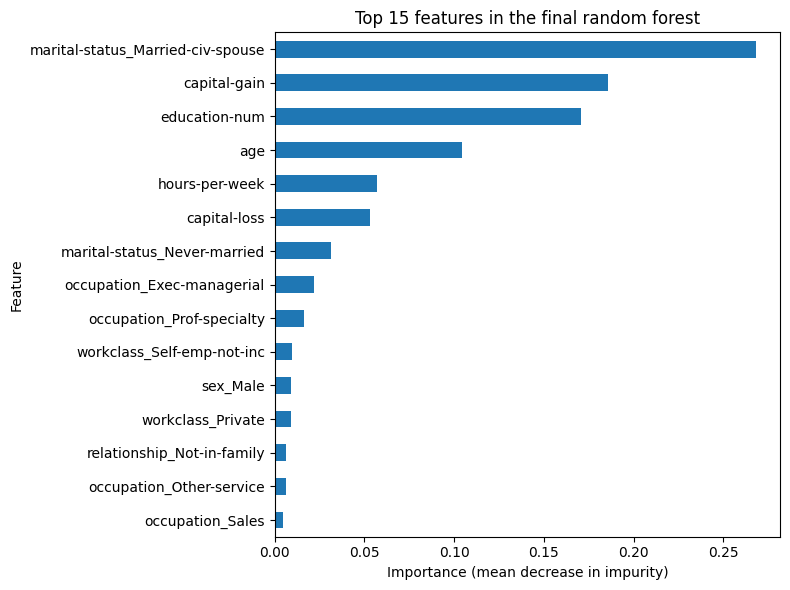

,feature,importance
12,marital-status_Married-civ-spouse,0.268
2,capital-gain,0.186
1,education-num,0.171
0,age,0.104
4,hours-per-week,0.057
3,capital-loss,0.053
14,marital-status_Never-married,0.031
19,occupation_Exec-managerial,0.022
25,occupation_Prof-specialty,0.016
8,workclass_Self-emp-not-inc,0.009


In [54]:
# feature importance for the final random forest (same method as the class lab)
importance_df = pd.DataFrame({'feature': X_train_base.columns,
                              'importance': rf_final.feature_importances_})
importance_df = importance_df.sort_values('importance', ascending=False).head(15)

ax = importance_df.plot(kind='barh', x='feature', y='importance', legend=False, figsize=(8, 6))
ax.invert_yaxis()  # most important at the top
ax.set_xlabel('Importance (mean decrease in impurity)')
ax.set_ylabel('Feature')
ax.set_title('Top 15 features in the final random forest')
plt.tight_layout()
plt.show()

importance_df.round(3)

FEATURE IMPORTANCE (final random forest)
- top: married-civ-spouse 0.218, education-num 0.198, age 0.118, hours-per-week 0.078
- top 4 = ~61% of importance
- then never-married 0.073, exec-managerial 0.044, not-in-family 0.039, prof-specialty 0.036, sex_male 0.032
- marital-status + relationship columns overlap (husband/wife = married), signal counted twice
- sex_male #9: model uses sex; fairness question for the advisor firm (would steer calls to men)
- method favors numeric columns, read as rough ranking
- all top features known before income, no leakage concern

In [55]:
# subgroup check: how does the final random forest perform for different groups on the test set?
from sklearn.metrics import precision_score

sub = X_test_base.copy()
sub['actual'] = y_test.values
sub['pred'] = test_preds

# rebuild readable group labels from the 0/1 columns
sub['sex'] = np.where(sub['sex_Male'] == 1, 'Male', 'Female')
race_cols = [c for c in sub.columns if c.startswith('race_')]
sub['race'] = sub[race_cols].idxmax(axis=1).str.replace('race_', '')
sub.loc[sub[race_cols].sum(axis=1) == 0, 'race'] = 'Amer-Indian-Eskimo'   # the dropped (first) category
sub['age group'] = pd.cut(sub['age'], [16, 25, 35, 45, 55, 65, 100],
                          labels=['17-25', '26-35', '36-45', '46-55', '56-65', '66+'])

def group_report(col):
    rows = []
    for g, d in sub.groupby(col, observed=True):
        rows.append({col: g, 'count': len(d),
                     'actual share >50K': d['actual'].mean(),
                     'predicted share >50K': d['pred'].mean(),
                     'accuracy': accuracy_score(d['actual'], d['pred']),
                     'recall': recall_score(d['actual'], d['pred'], zero_division=0),
                     'precision': precision_score(d['actual'], d['pred'], zero_division=0)})
    return pd.DataFrame(rows).set_index(col).round(3)

for col in ['sex', 'race', 'age group']:
    print(group_report(col), '\n')

        count  actual share >50K  predicted share >50K  accuracy  recall  \
sex                                                                        
Female   2984              0.118                 0.078     0.926   0.516   
Male     6061              0.312                 0.251     0.826   0.623   

        precision  
sex                
Female      0.781  
Male        0.774   

                    count  actual share >50K  predicted share >50K  accuracy  \
race                                                                           
Amer-Indian-Eskimo     96              0.083                 0.073     0.906   
Asian-Pac-Islander    268              0.272                 0.235     0.828   
Black                 849              0.124                 0.080     0.926   
Other                  68              0.132                 0.088     0.926   
White                7764              0.264                 0.207     0.851   

                    recall  precision  
race        

In [36]:
# threshold choice by cost, IRS perspective: mail higher-income filing materials to people flagged as >50K
# cost of a missed high earner = P(no on-time filing) x tax owed x share never collected
# sourced: mailing ≈ $1 (82¢ USPS stamp + printing); 91% of the tax gap is never collected (IRS IR-2023-187: $625B / $688B)
# assumptions: 5% of missed high earners don't file on time (~2x the ~2.5% penalized late-filing rate, IRS Data Book Table 4-2)
#              ~$11,000 tax owed (≈10% effective rate on ~$110K; Tax Foundation puts the next band up at 14.3%)
from sklearn.metrics import precision_score

action_cost = 1.00
late_share, tax_owed, uncollected = 0.05, 11000, 0.91
miss_cost = late_share * tax_owed * uncollected      # ≈ $500

def cost_per_1000(y_true, sent, a_cost, m_cost):
    y_true, sent = np.asarray(y_true), np.asarray(sent).astype(bool)
    missed = (~sent & (y_true == 1)).sum()
    return (sent.sum() * a_cost + missed * m_cost) / len(y_true) * 1000

thresholds = np.round(np.arange(0.01, 0.91, 0.01), 2)

# 1. pick the threshold on TRAINING data only (out-of-fold predictions)
rf_cv_model = RandomForestClassifier(n_estimators=500, max_depth=20, min_samples_leaf=5,
                                     max_features=0.5, random_state=0, n_jobs=-1)
train_probs = cross_val_predict(rf_cv_model, X_train_base, y_train, cv=cv, method='predict_proba')[:, 1]

costs = [cost_per_1000(y_train, train_probs >= t, action_cost, miss_cost) for t in thresholds]
best_t = thresholds[int(np.argmin(costs))]
print(f'Main scenario: mailing ${action_cost:.2f}, missed high earner ${miss_cost:,.0f} → best threshold (train): {best_t}')

# 2. check ONCE on the test set vs. no-model policies
n = len(y_test)
policies = {'Send to no one': np.zeros(n, bool), 'Send to everyone': np.ones(n, bool),
            'Model, threshold 0.50': test_probs >= 0.5, f'Model, threshold {best_t}': test_probs >= best_t}
print('\nTest set:')
for name, sent in policies.items():
    print(f'{name:26s} cost per 1,000: ${cost_per_1000(y_test, sent, action_cost, miss_cost):,.0f}   '
          f'sent: {sent.sum():,}   high earners caught: {recall_score(y_test, sent):.1%}')

# 3. sensitivity: when does the model beat the best no-model policy? (training data)
rows = []
for a_cost, a_name in [(1.00, 'letter ($1)'), (25, 'phone call ($25)'), (100, 'caseworker contact ($100)')]:
    for share in [0.025, 0.05, 0.10]:
        m_cost = share * tax_owed * uncollected
        c = [cost_per_1000(y_train, train_probs >= t, a_cost, m_cost) for t in thresholds]
        everyone = cost_per_1000(y_train, np.ones(len(y_train), bool), a_cost, m_cost)
        no_one = cost_per_1000(y_train, np.zeros(len(y_train), bool), a_cost, m_cost)
        rows.append({'action': a_name, 'share not filing': share, 'miss cost': round(m_cost),
                     'best threshold': thresholds[int(np.argmin(c))],
                     'model cost /1,000': round(min(c)), 'best no-model /1,000': round(min(everyone, no_one)),
                     'model saves /1,000': round(min(everyone, no_one) - min(c))})
print('\nSensitivity (training data):')
print(pd.DataFrame(rows).to_string(index=False))

# 4. fairness: does the cost-based threshold shrink the recall gap between groups? (test set)
sex = np.where(X_test_base['sex_Male'] == 1, 'Male', 'Female')
race = X_test_base[[c for c in X_test_base.columns if c.startswith('race_')]].idxmax(axis=1).str.replace('race_', '').values
rows = []
for label, grp in [('Female', sex == 'Female'), ('Male', sex == 'Male'),
                   ('Black', race == 'Black'), ('White', race == 'White')]:
    yt, pt = y_test.values[grp], test_probs[grp]
    rows.append({'group': label,
                 'recall @ 0.50': recall_score(yt, pt >= 0.5), f'recall @ {best_t}': recall_score(yt, pt >= best_t),
                 'precision @ 0.50': precision_score(yt, pt >= 0.5), f'precision @ {best_t}': precision_score(yt, pt >= best_t)})
print('\nRecall and precision by group (test set):')
print(pd.DataFrame(rows).set_index('group').round(3))

Main scenario: mailing $1.00, missed high earner $500 → best threshold (train): 0.01

Test set:
Send to no one             cost per 1,000: $124,060   sent: 0   high earners caught: 0.0%
Send to everyone           cost per 1,000: $1,000   sent: 9,045   high earners caught: 100.0%
Model, threshold 0.50      cost per 1,000: $49,109   sent: 1,752   high earners caught: 60.6%
Model, threshold 0.01      cost per 1,000: $1,939   sent: 6,531   high earners caught: 99.0%

Sensitivity (training data):
                   action  share not filing  miss cost  best threshold  model cost /1,000  best no-model /1,000  model saves /1,000
              letter ($1)             0.025        250            0.01               1014                  1000                 -14
              letter ($1)             0.050        500            0.01               1298                  1000                -298
              letter ($1)             0.100       1001            0.01               1865                  

In [35]:
# error diagnosis: who does the final model get wrong, and how are they different?
err = X_test_base.copy()
err['actual'] = y_test.values
err['predicted'] = test_preds
err['prob_>50K'] = test_probs

err['group'] = np.select(
    [(err['actual'] == 1) & (err['predicted'] == 1),
     (err['actual'] == 1) & (err['predicted'] == 0),
     (err['actual'] == 0) & (err['predicted'] == 1),
     (err['actual'] == 0) & (err['predicted'] == 0)],
    ['1. caught high earner', '2. MISSED high earner', '3. WRONGLY flagged', '4. correctly skipped'],
    default='other')

compare_cols = {
    'age': 'avg age',
    'education-num': 'avg education (1-16)',
    'hours-per-week': 'avg hours/week',
    'capital-gain': 'avg capital gain',
    'marital-status_Married-civ-spouse': 'share married',
    'sex_Male': 'share male',
    'occupation_Exec-managerial': 'share exec/managerial',
    'occupation_Prof-specialty': 'share professional',
    'prob_>50K': 'avg model probability',
}
summary = err.groupby('group')[list(compare_cols)].mean().rename(columns=compare_cols)
summary.insert(0, 'count', err['group'].value_counts().sort_index())
summary.round(2)

,count,avg age,avg education (1-16),avg hours/week,avg capital gain,share married,share male,share exec/managerial,share professional,avg model probability
group,,,,,,,,,,
1. caught high earner,1358,45.11,12.40,46.38,6671.81,0.92,0.87,0.32,0.31,0.81
2. MISSED high earner,884,42.43,10.30,44.46,132.61,0.74,0.81,0.13,0.13,0.29
3. WRONGLY flagged,394,44.17,12.05,45.75,439.16,0.95,0.87,0.32,0.30,0.65
4. correctly skipped,6409,36.16,9.48,38.82,138.94,0.30,0.60,0.08,0.08,0.09


In [32]:
# threshold choice by cost, tax-prep firm perspective (new clients, decided from the intake questionnaire)
# false positive (wrongly flagged): ~1 hour of preparer time on a higher-income package the client didn't need
#   sourced: tax preparer mean wage $27.96/hr (BLS OEWS, May 2023: bls.gov/oes/2023/may/oes132082.htm)
# false negative (missed high earner): once we take them on as a client, the firm absorbs the late-filing penalty
#   (accuracy guarantee), assumed for 10% of missed high earners
#   sourced: avg IRS late-filing penalty ≈ $1,615 (IRS Data Book FY2025 Table 4-2: $6.48B / 4.01M)
from sklearn.metrics import precision_score

wage, penalty = 27.96, 1615
fp_cost = 1 * wage                 # ≈ $28
late_share = 0.10
fn_cost = late_share * penalty     # ≈ $162

def cost_per_1000(y_true, flagged, fp_c, fn_c):
    y_true, flagged = np.asarray(y_true), np.asarray(flagged).astype(bool)
    fp = (flagged & (y_true == 0)).sum()
    fn = (~flagged & (y_true == 1)).sum()
    return (fp * fp_c + fn * fn_c) / len(y_true) * 1000

thresholds = np.round(np.arange(0.01, 0.91, 0.01), 2)

# 1. pick the threshold on TRAINING data only (out-of-fold predictions)
rf_cv_model = RandomForestClassifier(n_estimators=500, max_depth=20, min_samples_leaf=5,
                                     max_features=0.5, random_state=0, n_jobs=-1)
train_probs = cross_val_predict(rf_cv_model, X_train_base, y_train, cv=cv, method='predict_proba')[:, 1]

costs = [cost_per_1000(y_train, train_probs >= t, fp_cost, fn_cost) for t in thresholds]
best_t = thresholds[int(np.argmin(costs))]
print(f'False positive ${fp_cost:.0f}, false negative ${fn_cost:.0f} → best threshold (train): {best_t}')

# 2. check ONCE on the test set vs. no-model policies
n = len(y_test)
policies = {'Flag no one (all basic)': np.zeros(n, bool), 'Flag everyone (all high-income)': np.ones(n, bool),
            'Model, threshold 0.50': test_probs >= 0.5, f'Model, threshold {best_t}': test_probs >= best_t}
print('\nTest set:')
for name, flagged in policies.items():
    print(f'{name:32s} cost per 1,000 clients: ${cost_per_1000(y_test, flagged, fp_cost, fn_cost):,.0f}   '
          f'flagged: {flagged.sum():,}   high earners caught: {recall_score(y_test, flagged):.1%}   '
          f'precision: {precision_score(y_test, flagged, zero_division=0):.1%}')

# 3. sensitivity: how does the answer change with the assumptions? (training data)
rows = []
for fp_h in [0.5, 1, 2]:
    for share in [0.05, 0.10, 0.20]:
        fp_c, fn_c = fp_h * wage, share * penalty
        c = [cost_per_1000(y_train, train_probs >= t, fp_c, fn_c) for t in thresholds]
        everyone = cost_per_1000(y_train, np.ones(len(y_train), bool), fp_c, fn_c)
        no_one = cost_per_1000(y_train, np.zeros(len(y_train), bool), fp_c, fn_c)
        rows.append({'FP hours': fp_h, 'share penalized': share, 'FP cost': round(fp_c), 'FN cost': round(fn_c),
                     'best threshold': thresholds[int(np.argmin(c))],
                     'model cost /1,000': round(min(c)), 'best no-model /1,000': round(min(everyone, no_one)),
                     'model saves /1,000': round(min(everyone, no_one) - min(c))})
print('\nSensitivity (training data):')
print(pd.DataFrame(rows).to_string(index=False))

# 4. fairness at the chosen threshold (test set)
sex = np.where(X_test_base['sex_Male'] == 1, 'Male', 'Female')
race = X_test_base[[c for c in X_test_base.columns if c.startswith('race_')]].idxmax(axis=1).str.replace('race_', '').values
rows = []
for label, grp in [('Female', sex == 'Female'), ('Male', sex == 'Male'),
                   ('Black', race == 'Black'), ('White', race == 'White')]:
    yt, pt = y_test.values[grp], test_probs[grp]
    rows.append({'group': label,
                 'recall @ 0.50': recall_score(yt, pt >= 0.5), f'recall @ {best_t}': recall_score(yt, pt >= best_t),
                 'precision @ 0.50': precision_score(yt, pt >= 0.5), f'precision @ {best_t}': precision_score(yt, pt >= best_t)})
print('\nRecall and precision by group (test set):')
print(pd.DataFrame(rows).set_index('group').round(3))

NameError: name 'X_train_base' is not defined